# TP 2 : Apprentissage Profond avec TensorFlow / Keras

**Nom :** Manar ELBIYAALI  |  **N° :** 12  |  **Filière :** ILIA2 – ENSA Fès
**Module :** Technologies IA  |  **Prof :** Youness IDRISSI KHAMLICHI

> Pour ce TP j'ai travaillé sur Google Colab. Les réponses aux questions sont écrites sous chaque partie, avec mes mots.

# Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)
## 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


**Q1. Différence entre TensorFlow et Keras ?**
TensorFlow est la bibliothèque de base (le "moteur") : elle manipule les tenseurs, fait les calculs sur CPU/GPU et calcule les gradients. Keras est l'API de haut niveau placée par-dessus (`tf.keras`) : elle permet de construire un réseau en quelques lignes (couches, compile, fit) sans écrire les calculs à la main.

**Q2. À quoi sert `Flatten` ?**
Elle transforme l'image 2D (28×28) en un vecteur 1D de 784 valeurs, car une couche `Dense` attend un vecteur en entrée et non une matrice. Elle n'a aucun paramètre à apprendre.

**Q3. Version de TensorFlow installée ?**
Elle s'affiche avec le `print` ci-dessus (sur Colab, c'est une version 2.x récente). *(voir la sortie de la cellule)*

**Q4. À quoi servent `Sequential` et `Dense` ?**
`Sequential` permet d'empiler les couches l'une après l'autre, dans un ordre linéaire (la sortie d'une couche est l'entrée de la suivante). `Dense` est une couche entièrement connectée : chaque neurone est relié à tous les neurones de la couche précédente (calcul `activation(W·x + b)`).

## 2. Chargement et préparation du dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Type avant normalisation :", x_train.dtype)
print("Valeurs min/max avant :", x_train.min(), x_train.max())

# Normalisation
x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("Type après normalisation :", x_train.dtype)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Type avant normalisation : uint8
Valeurs min/max avant : 0 255
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
Type après normalisation : float64


**Q1. Pourquoi normalise-t-on les pixels ?**
Les pixels vont de 0 à 255. En les ramenant entre 0 et 1, les valeurs sont petites et du même ordre de grandeur : les gradients restent stables et l'optimiseur converge plus vite et plus facilement.

**Q2. Taille et type d'une image ?**
28×28 pixels en niveaux de gris (1 seul canal). Avant normalisation le type est `uint8` (entiers 0–255), après la division par 255.0 il devient `float64`.

**Q3. Nombre d'exemples d'entraînement ?**
60 000 images d'entraînement (et 10 000 pour le test, soit 70 000 au total).

## 3. Visualisation d'échantillons

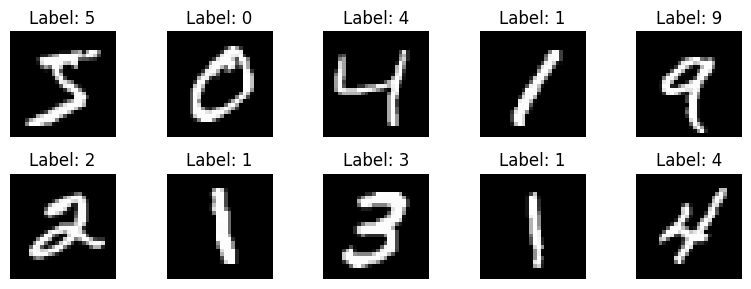

In [3]:
plt.figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

**À faire :** les chiffres affichés sont ceux des premières images du jeu d'entraînement (le premier est un 5, puis 0, 4, 1, 9…). Les labels affichés au-dessus correspondent bien aux images.

**Q1. Commande pour changer le nombre d'images ?**
Il faut modifier `range(10)` (nombre d'images) et la grille `plt.subplot(lignes, colonnes, i+1)`. Par exemple `range(20)` avec `plt.subplot(4,5,i+1)`.

**Q2. Que représente `cmap='gray'` ?**
C'est la palette de couleurs : elle affiche les valeurs en niveaux de gris. Sans ça, matplotlib utiliserait sa palette par défaut (viridis, jaune/violet).

**Q3. Utilité de cette étape ?**
Vérifier que les données sont bien chargées, que les labels correspondent aux images et se rendre compte de la qualité des données (écritures variées, ambiguës…) avant d'entraîner.

## 4. Construction du modèle

In [4]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**Q1. Nombre de paramètres ?**
- Dense(128) : 784 × 128 + 128 = 100 480
- Dense(10) : 128 × 10 + 10 = 1 290
- **Total = 101 770 paramètres** (Flatten : 0)

**Q2. Activation de la couche de sortie ?**
`softmax`, parce qu'on a un problème de classification multiclasse (10 chiffres) : softmax transforme les 10 sorties en probabilités positives dont la somme vaut 1, et on prend la classe de plus forte probabilité.

**Q3. Différence ReLU / Softmax ?**
ReLU = `max(0, x)` : appliquée neurone par neurone dans les couches cachées, elle introduit la non-linéarité et évite le problème de gradient qui disparaît. Softmax est utilisée en sortie : elle normalise tout le vecteur en probabilités.

## 5. Compilation du modèle

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

**Q1. Qu'est-ce qu'un optimiseur ?**
C'est l'algorithme qui met à jour les poids du réseau (à partir des gradients calculés par la rétropropagation) pour diminuer la perte. Exemples : SGD, RMSprop, Adam.

**Q2. Pourquoi une fonction de perte ?**
Elle mesure l'écart entre la prédiction et la vraie valeur. Sans elle le modèle ne saurait pas s'il se trompe ni dans quelle direction corriger ses poids : c'est ce qu'on cherche à minimiser.

**Q3. Si on change la fonction de perte ?**
Le modèle optimise un autre critère, donc le comportement change. Si elle n'est pas adaptée au problème (ex. MSE pour de la classification, ou `categorical_crossentropy` avec des labels entiers) l'apprentissage est moins efficace ou provoque même une erreur.

**Q4. Conséquence d'un mauvais optimiseur ?**
Convergence très lente, perte qui oscille ou diverge (learning rate mal adapté), ou blocage dans un mauvais minimum : on obtient une précision plus faible pour le même nombre d'époques.

**Q5. Différence `loss` / `metrics` ?**
La `loss` est ce que l'optimiseur minimise pendant l'entraînement (elle doit être dérivable). Les `metrics` (ex. accuracy) servent seulement à évaluer et à suivre les performances de façon lisible pour l'humain ; elles n'influencent pas l'apprentissage.

## 6. Entraînement du modèle

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.9275 - loss: 0.2566 - val_accuracy: 0.9576 - val_loss: 0.1406
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9661 - loss: 0.1113 - val_accuracy: 0.9696 - val_loss: 0.0991
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9766 - loss: 0.0782 - val_accuracy: 0.9691 - val_loss: 0.0972
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9829 - loss: 0.0574 - val_accuracy: 0.9730 - val_loss: 0.0918
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9858 - loss: 0.0457 - val_accuracy: 0.9780 - val_loss: 0.0735


**À observer :** la précision d'entraînement augmente à chaque époque et la perte diminue ; la précision de validation suit globalement la même tendance et reste proche de celle d'entraînement. *(voir les valeurs affichées ci-dessus)*

**Q1. Qu'est-ce qu'une époque ?**
Un passage complet du modèle sur tout le jeu d'entraînement (les 60 000 images, par paquets de 32 ici).

**Q2. Pourquoi un jeu de validation ?**
Pour mesurer, après chaque époque, la performance sur des données non utilisées pour ajuster les poids. Ça permet de détecter le surapprentissage et de régler les hyperparamètres.

**Q3. Avec 50 époques ?**
L'entraînement est plus long ; la précision d'entraînement continue de monter (proche de 100 %) mais la validation se stabilise, voire baisse : le modèle risque de **surapprendre** (apprendre par cœur le train). On utiliserait alors l'Early Stopping.

## 7. Évaluation du modèle

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9780 - loss: 0.0735
Test accuracy: 0.9780
Test loss: 0.0735


**Q1. Précision finale ?**
Elle est donnée par `Test accuracy` ci-dessus. Pour ce type de réseau simple sur MNIST on obtient environ 97–98 %. **→ Recopier ici ma valeur exacte : ........**

**Q2. Pourquoi test < entraînement ?**
Le modèle a ajusté ses poids sur les données d'entraînement, donc il les connaît mieux. Sur des images jamais vues, il généralise un peu moins bien.

**Q3. Que faire en cas de surapprentissage ?**
Ajouter du Dropout, de la régularisation L2, réduire la taille du modèle, arrêter plus tôt (Early Stopping), augmenter les données (data augmentation) ou en récolter davantage.

## 8. Visualisation des performances

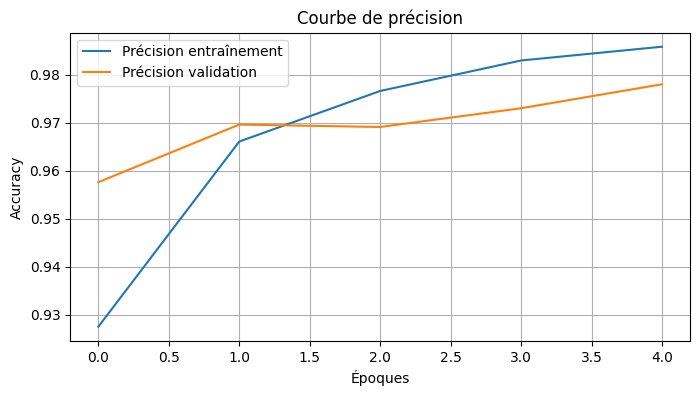

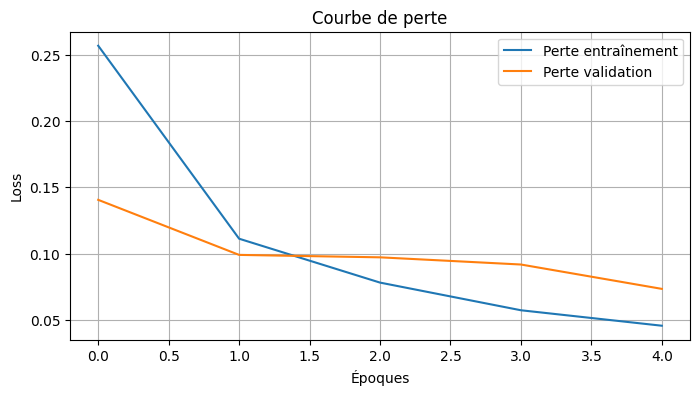

In [8]:
plt.figure(figsize=(8,4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Courbe de perte (demandée dans le rapport)
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

**Q1. Que remarque-t-on ?**
La précision monte rapidement dès les premières époques puis se stabilise ; la courbe de validation reste proche de celle d'entraînement. La perte diminue de manière correspondante.

**Q2. Comment détecter visuellement le surapprentissage ?**
Quand la précision d'entraînement continue de monter alors que celle de validation stagne ou baisse (et que la perte de validation remonte) : un écart qui se creuse entre les deux courbes.

**Q3. Stratégies pour y remédier ?**
Dropout, régularisation, Early Stopping, data augmentation, modèle plus petit, plus de données.

**Q4. Si les deux courbes divergent ?**
C'est le signe d'overfitting : j'arrête l'entraînement au meilleur point, j'ajoute de la régularisation/Dropout ou je simplifie le modèle.

## 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


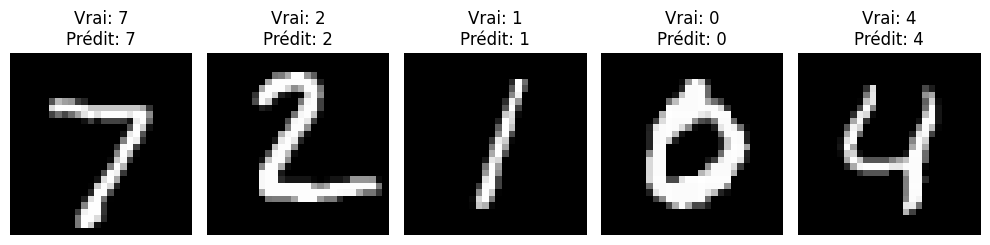

Nombre d'erreurs sur le test : 220 sur 10000


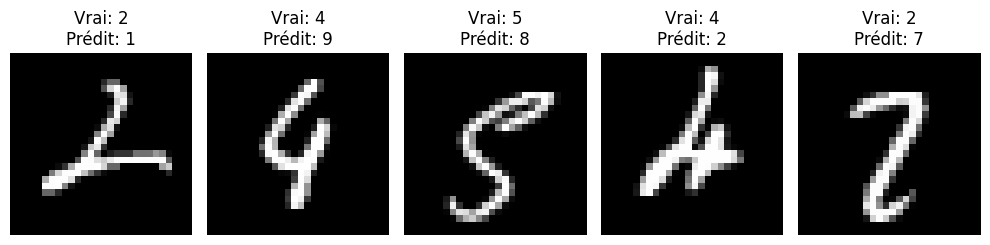

In [9]:
predictions = model.predict(x_test)

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

# Pour trouver les erreurs du modèle
y_pred_classes = np.argmax(predictions, axis=1)
erreurs = np.where(y_pred_classes != y_test)[0]
print("Nombre d'erreurs sur le test :", len(erreurs), "sur", len(y_test))

plt.figure(figsize=(10,4))
for k, i in enumerate(erreurs[:5]):
    plt.subplot(1,5,k+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {y_pred_classes[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

**Q1. Le modèle fait-il des erreurs ?**
Oui, quelques-unes (environ 2–3 % des images). Sur les 5 premières images il n'y en a généralement pas ; les erreurs apparaissent sur des chiffres mal écrits ou ambigus (4/9, 3/5, 7/1…), visibles dans la 2e figure.

**Q2. Comment expliquer une prédiction erronée ?**
Écriture très différente ou ambiguë, chiffres qui se ressemblent, et surtout limite du modèle dense : il ne tient pas compte de la structure spatiale de l'image (il met tous les pixels à plat).

**Q3. Technique pour améliorer ?**
Un réseau convolutif (CNN), éventuellement avec Dropout et data augmentation.

## Travail demandé : analyse personnelle (Exercice 1)

- **Interprétation :** le réseau dense à une couche cachée atteint environ 97–98 % de précision sur MNIST en seulement 5 époques. Les courbes montrent un apprentissage rapide et pas de gros écart train/validation, donc peu de surapprentissage à 5 époques.
- **Difficultés :** comprendre la différence entre `loss` et `metrics`, et le choix de `sparse_categorical_crossentropy` (labels entiers, sans one-hot).
- **Améliorations :** ajouter des couches ou des neurones, du Dropout, tester d'autres activations/optimiseurs/learning rate, et surtout passer à un CNN.

---
# Exercice 2 : Classification d'images avec Fashion-MNIST

In [10]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Étape 1 – Exploration du jeu de données

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des données : uint8


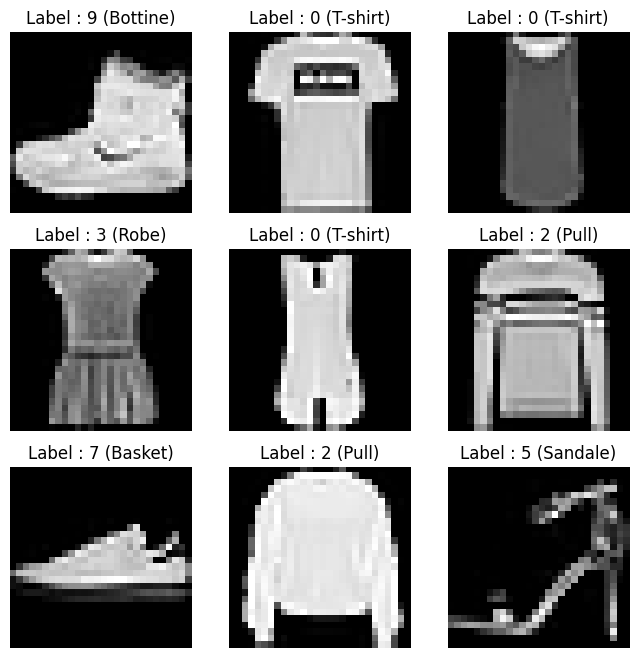

In [11]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des données :", X_train.dtype)

class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.show()

**Question : nature des données et taille des images ?**
Ce sont des images de vêtements et accessoires (T-shirt, pantalon, chaussures, sac…), en niveaux de gris, de petite taille (28×28 pixels), centrées, avec 10 classes. Le train contient 60 000 images et le test 10 000. Le dataset est plus difficile que MNIST car certaines classes se ressemblent beaucoup (T-shirt / chemise / pull / manteau).

## Étape 2 – Prétraitement des données

In [12]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(y_train[0], "->", y_train_cat[0])

9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


**Q1. Pourquoi normaliser ?**
Pour mettre toutes les entrées à la même échelle (0–1), ce qui stabilise l'apprentissage et accélère la convergence.

**Q2. Importance du one-hot encoding ?**
Les classes sont des catégories sans ordre. Avec un label entier (ex. 3), le modèle pourrait croire que "3" est plus grand ou proche de "2". Le one-hot représente chaque classe par un vecteur indépendant, compatible avec la sortie softmax et la `categorical_crossentropy`.

## Étape 3 – Modèle dense (ANN)

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Nombre de paramètres : 100 480 + 8 256 + 650 = **109 386**.

In [14]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7830 - loss: 0.6206 - val_accuracy: 0.8402 - val_loss: 0.4434
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8460 - loss: 0.4259 - val_accuracy: 0.8524 - val_loss: 0.3993
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8603 - loss: 0.3839 - val_accuracy: 0.8585 - val_loss: 0.3808
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8690 - loss: 0.3579 - val_accuracy: 0.8641 - val_loss: 0.3670
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8763 - loss: 0.3403 - val_accuracy: 0.8657 - val_loss: 0.3572
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8805 - loss: 0.3245 - val_accuracy: 0.8723 - val_loss: 0.3434
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8860 - loss: 0.3114 - val_accuracy: 0.8660 - val_loss: 0.3564
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8892 - loss: 0.3041 - val_accuracy: 0.

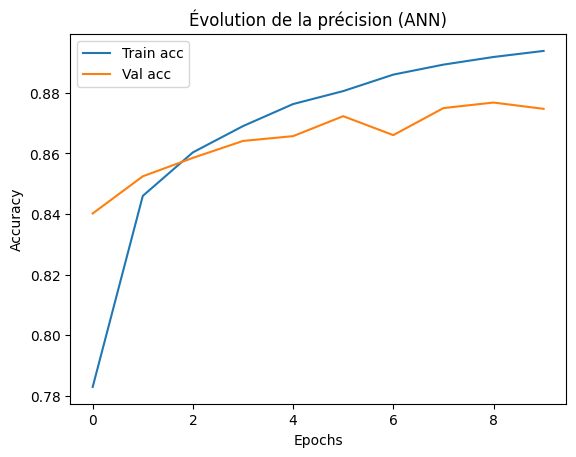

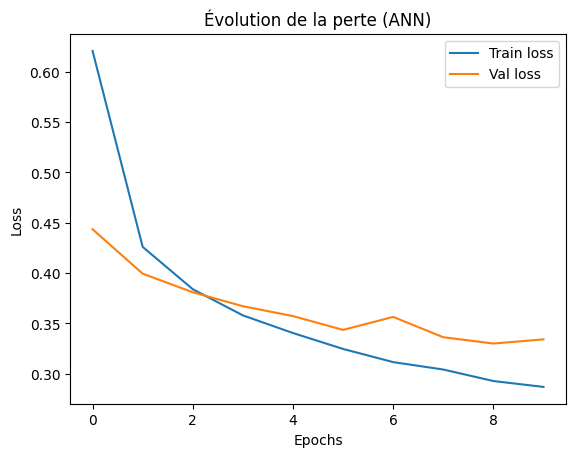

In [15]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

**Q1. Pourquoi ReLU ici ?**
Elle est simple et rapide à calculer, elle introduit la non-linéarité nécessaire et limite le problème de disparition du gradient (contrairement à sigmoïde/tanh), donc l'entraînement est plus efficace.

**Q2. Différence entre `accuracy` et `val_accuracy` ?**
`accuracy` est la précision sur les données d'entraînement (utilisées pour ajuster les poids) ; `val_accuracy` est la précision sur les 20 % mis de côté pour la validation, jamais utilisés pour mettre à jour les poids : elle indique la capacité de généralisation.

**Q3. Avec 50 époques ?**
La précision d'entraînement continue d'augmenter alors que celle de validation stagne puis peut baisser : surapprentissage (la perte de validation remonte). Le temps de calcul augmente aussi.

In [16]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8704 - loss: 0.3586
Précision sur le test set : 0.8704000115394592


**Précision ANN sur le test :** environ 0.87–0.88 *(→ noter ma valeur : ........)*.

## Étape 4 — Fonctions d'activation
Comparaison de sigmoïde, tanh, ReLU et LeakyReLU.

{'sigmoid': 0.8622499704360962, 'tanh': 0.8700000047683716, 'relu': 0.8778333067893982, 'LeakyReLU': 0.874833345413208}


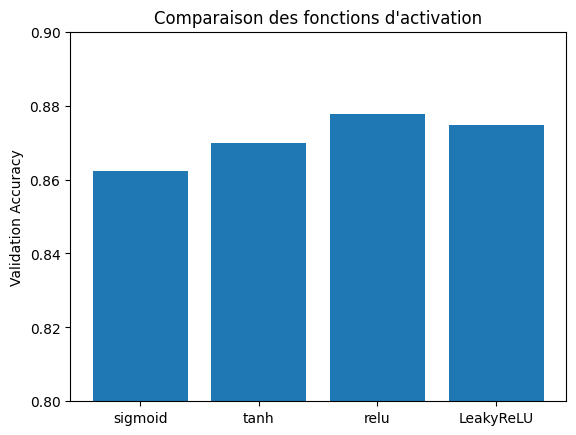

In [17]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28,28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

print(results)

plt.bar(list(results.keys()), list(results.values()))
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.ylim(0.8, 0.9)
plt.show()

**Q1. Quelle fonction donne les meilleurs résultats ?**
D'après le graphique ci-dessus, ce sont en général ReLU et LeakyReLU qui sont les meilleures (ou très proches de tanh), et sigmoïde est souvent la plus faible. *(→ vérifier avec mes valeurs : meilleure = ........)*

**Q2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
Elles saturent pour les grandes valeurs (sorties proches de 0/1 ou -1/1) : le gradient devient presque nul, c'est le problème du *vanishing gradient*, et l'apprentissage devient lent surtout dans les réseaux profonds. Elles coûtent aussi plus cher à calculer (exponentielles). Sigmoïde n'est pas centrée sur 0.

**Q3. À quoi sert LeakyReLU ?**
Elle laisse passer une petite pente (ici 0.1) pour les valeurs négatives au lieu de mettre 0 : ça évite les "neurones morts" de ReLU qui ne se mettent plus jamais à jour.

## Étape 5 : Modèle CNN

In [18]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Ajout de la dimension "canal"
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Nombre de paramètres du CNN : 320 + 18 496 + 204 928 + 1 290 = **225 034**.

In [ ]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - accuracy: 0.7801 - loss: 0.6145 - val_accuracy: 0.8553 - val_loss: 0.4025
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.8593 - loss: 0.3886 - val_accuracy: 0.8744 - val_loss: 0.3437
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.8768 - loss: 0.3374 - val_accuracy: 0.8846 - val_loss: 0.3122
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.8880 - loss: 0.3066 - val_accuracy: 0.8883 - val_loss: 0.2992
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 100ms/step - accuracy: 0.8944 - loss: 0.2864 - val_accuracy: 0.8925 - val_loss: 0.2888
Epoch 6/10
  7/375 ━━━━━━━━━━━━━━━━━━━━ 31s 85ms/step - accuracy: 0.9063 - loss: 0.2359

In [ ]:
plt.plot(history_cnn.history['accuracy'], label='Train acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (CNN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

plt.plot(history_cnn.history['loss'], label='Train loss')
plt.plot(history_cnn.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (CNN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

**Q1. Différence entre ANN et CNN ?**
Un ANN (dense) relie chaque pixel à chaque neurone après avoir aplati l'image, donc il perd la structure 2D et a beaucoup de paramètres. Un CNN utilise des filtres de convolution qui parcourent l'image et détectent des motifs locaux (bords, textures, formes), avec des poids partagés.

**Q2. Pourquoi le CNN est meilleur ?**
Il exploite la structure spatiale de l'image, apprend des caractéristiques hiérarchiques (simples puis complexes) et est plus robuste aux petits décalages grâce au partage de poids et au pooling. Ici on passe d'environ 88 % (ANN) à environ 91–92 % (CNN). *(→ noter mes valeurs : ........)*

**Q3. Rôle du Pooling ?**
Il réduit la taille des cartes de caractéristiques (ici ÷2) : moins de calculs et de paramètres, plus d'invariance aux petites translations, et un peu moins de surapprentissage.

## Étape 6 — Matrice de confusion

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names,
                                        cmap="Blues", ax=ax, xticks_rotation=45)
plt.title("Matrice de confusion - CNN")
plt.show()

**Q1. Classes les plus confondues ?**
Surtout **T-shirt ↔ Chemise**, **Chemise ↔ Pull/Manteau** et un peu Pull ↔ Manteau : ce sont des vêtements du haut avec des formes très proches. Les classes comme Pantalon, Sac, Basket ou Bottine sont presque toujours bien reconnues.

**Q2. Comment réduire ces erreurs ?**
Un CNN plus profond, plus d'époques avec Early Stopping, Batch Normalization, data augmentation, réglage des hyperparamètres (learning rate, batch size), ou du transfer learning.

## Étape 7 : Data Augmentation

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

# Nouveau CNN identique pour comparer équitablement avec le premier
cnn_aug = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn_aug.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_aug = cnn_aug.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

test_loss, test_acc = cnn_aug.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN + augmentation sur test set :", test_acc)

**Q1. Intérêt de la Data Augmentation ?**
Elle crée de nouvelles images à partir des existantes (rotation, zoom, flip…) : le modèle voit plus de variations, généralise mieux et surapprend moins, sans collecter de nouvelles données.

**Q2. Transformations les plus efficaces pour ce dataset ?**
Le flip horizontal est pertinent car un vêtement ou une chaussure retournée reste réaliste ; les petites rotations et petits zooms aussi. Un flip vertical serait peu utile (un pantalon à l'envers n'existe pas dans les données).

## Analyse personnelle finale

- **Interprétation des résultats :** sur MNIST le réseau dense simple atteint environ 97–98 %. Sur Fashion-MNIST, plus difficile, l'ANN atteint environ 88 % et le CNN environ 91–92 %, ce qui confirme l'intérêt des convolutions pour les images. Les erreurs concernent surtout les vêtements qui se ressemblent (T-shirt/chemise/pull).
- **Difficultés rencontrées :** comprendre la différence entre `sparse_categorical_crossentropy` (labels entiers) et `categorical_crossentropy` (one-hot), comprendre les formes (shape) des entrées pour le CNN (ajout de la dimension canal) et le temps d'entraînement.
- **Propositions d'amélioration :** ajouter des couches ou plus de filtres, Batch Normalization, Early Stopping, ajuster le learning rate et le batch size, et utiliser la data augmentation.